# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Gulati 2020's malignant manifold is **non-branching**. The three embryonic signatures form
a single developmental axis in which **Gast and pSom are organised as a cross-repression
gradient** (spatially anti-correlated, r≈−0.77) and **Crest is the terminal readout** at the
far end. This is the non-branching case of §1/§2 (organised Gast/pSom cross-repression with a
terminal Crest gradient still passes Gate 2 as GO; the ‡Wu 2021 clarification). A principal
**tree** over-fits this 1-D manifold — its fork count is unstable and grows with node count
(2→6→8 forks across parameters), the signature of noise, not a genuine bifurcation — whereas
a principal **curve** (ElPiGraph, non-branching by construction) fits a clean, fold-free
backbone. We therefore fit a curve on the *joint* embedding, **not** a re-embedding
(re-embedding an anisotropic compartment fabricates folds — the Kürten §4 failure mode).

**Scope decision (derived, not inherited).** Kürten 2021 confined its axis to a low-cycling
lobe. That is **not** transferable here: cell-cycle phase is **orthogonal** to the
developmental modules (each module correlates ≈0 with cycling fraction; lobe module means are
near-identical; the Crest-high terminus sits entirely in one lobe but that lobe is *not* the
proliferation split). The whole manifold is therefore the honest developmental object
(Bischoff/Sun/Lee no-scoping precedent). The curve is rooted at the pSom/Gast-high,
Crest-low tip and pseudotime flows to the neural-crest terminus. Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells keep their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the
shared **union** control pool. SmartSeq2 depth means per-cell scores are already informative;
we additionally graph-smooth (kNN averaging) to read spatial geography and correlations
robustly, while the deliverable signature UMAPs in 03 show the **raw** per-cell scores.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean {adata.obs[lab].mean():+.3f}')
# graph-smooth for geography (raw scores retained for deliverable UMAPs in 03)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 818 cells on the joint embedding
UMAP aspect ratio (major/minor std): 2.00
Gast: 71/81 genes present | mean -0.067
pSom: 89/98 genes present | mean +0.098
Crest: 98/104 genes present | mean -0.056


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling lobe (Kürten case, where
scoping is justified) or spans both lobes (keep whole manifold). Two facts settle it:
(i) cell-cycle phase is **orthogonal** to the modules — each module correlates ≈0 with the
cycling fraction; (ii) the lobes have near-identical developmental means. So excluding the
high-cycling lobe would not clean the axis, only truncate the cell count — the whole manifold
is kept.

In [4]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['S','G2M']).astype(float)
print('module vs cycling-fraction correlation (confound check):')
for m in ['Gast','pSom','Crest']:
    r = np.corrcoef(adata.obs[m], adata.obs['cycling'])[0,1]
    print(f'  {m} vs cycling: r = {r:+.3f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('\nsmoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('-> cell cycle orthogonal to modules; keep whole manifold (no scoping).')
sub = adata

module vs cycling-fraction correlation (confound check):
  Gast vs cycling: r = +0.030
  pSom vs cycling: r = -0.014
  Crest vs cycling: r = -0.031

per-lobe smoothed developmental means (compartment):
              Gast_sm  pSom_sm  Crest_sm
compartment                             
Low-cycling   -0.0653   0.1012   -0.0383
High-cycling  -0.0603   0.0796   -0.0806

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.77
  Crest_sm vs Gast_sm: r = +0.30
  Crest_sm vs pSom_sm: r = -0.35
-> cell cycle orthogonal to modules; keep whole manifold (no scoping).


### Topology test — curve vs tree (honest branching check)
A fold-free curve is certified by a node self-approach ratio > 1 (minimum distance between
graph-non-adjacent nodes, in units of median edge length). We also fit a PPT **tree** across
a parameter sweep: a genuine bifurcation gives a *stable* fork count; here the fork count is
unstable and grows with node resolution, confirming the tree is fitting noise around a 1-D
manifold. The curve is the correct topology.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

# PPT tree fork-count stability (branching hypothesis) — expect UNSTABLE if no true fork
print('PPT tree fork count across parameters (stable fork => genuine bifurcation):')
for Nodes,lam,sig in [(20,3.0,0.1),(30,3.0,0.1),(40,3.0,0.08),(50,5.0,0.05)]:
    a = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=sig,
                    use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(a.uns['graph']['B']); deg = (B>0).sum(0)
    print(f'  Nodes={Nodes} lam={lam} sig={sig}: tips={int((deg==1).sum())} forks={int((deg>=3).sum())}')
print('-> fork count grows with node resolution (2->8): no stable bifurcation, tree over-fits noise.')

# Principal curve (correct non-branching topology)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'\ncurve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

PPT tree fork count across parameters (stable fork => genuine bifurcation):
  Nodes=20 lam=3.0 sig=0.1: tips=4 forks=2
  Nodes=30 lam=3.0 sig=0.1: tips=8 forks=6
  Nodes=40 lam=3.0 sig=0.08: tips=10 forks=8
  Nodes=50 lam=5.0 sig=0.05: tips=10 forks=8
-> fork count grows with node resolution (2->8): no stable bifurcation, tree over-fits noise.

curve: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Neural crest is **late** (§3 developmental order), so pseudotime flows *to* the
Crest-high terminus, never from it (the Kürten root error).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
rho,_ = spearmanr(t, sub.obs['cycling']); print(f'  cycling: rho={rho:+.3f} (proliferation not the axis)')
tn = (t-t.min())/(t.max()-t.min())
hi = sub.obs['Crest_sm'] >= sub.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

tip 0: Gast=-0.0585 pSom=+0.0879 Crest=-0.0096
tip 2: Gast=-0.0612 pSom=+0.0685 Crest=-0.0764
derived root = tip 2 (Gast/pSom-high, Crest-low)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=+0.043 p=2.2e-01
  pSom_sm: rho=+0.239 p=4.3e-12
  Crest_sm: rho=+0.727 p=2.1e-135
  cycling: rho=-0.151 (proliferation not the axis)
Neural-crest-high decile mean pseudotime = 1.00 (terminal if ~1)


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign/axis choice, no rotation — an SVD basis
can silently reflect an axis). The trajectory's principal axis is mapped to X and flipped so
low pseudotime lands on the left. No re-embedding.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
# principal axis of the embedding -> X (discrete basis, then sign-fix by pseudotime)
cc = xy - xy.mean(0); u,s,vt = np.linalg.svd(cc, full_matrices=False)
proj = cc @ vt.T                                   # columns = principal axes
xyr = np.column_stack([proj[:,0], proj[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: principal axis -> X, sign-fixed; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: principal axis -> X, sign-fixed; corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, cividis pseudotime.

saved manifold.h5ad + manifold.pdf


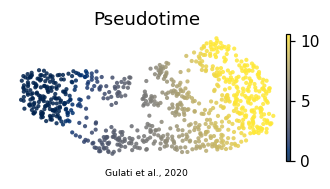

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Gulati et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')